# **Este cuaderno es para la tesis de Jonathan y Carlos**

#Clasificación de audio mediante redes neuronales convolucionales

La clasificación de audio se puede realizar convirtiendo secuencias de audio en espectrogramas (https://en.wikipedia.org/wiki/Spectrogram), que proporcionan representaciones visuales de los espectros de frecuencias a medida que varían con el tiempo, y clasificando los espectrogramas mediante redes neuronales convolucionales (CNN).

Este cuaderno es una adaptación de https://github.com/jeffprosise/Deep-Learning/blob/master/Audio%20Classification%20(CNN).ipynb


## Conexión al drive y guardado de directorios de trabajo

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
directorio_de_trabajo = "/content/drive/MyDrive/spectograms"

## Cuenta el número de espectogramas disponibles en cada lengua



Para la bitácora y otras funciones

In [3]:
import os
numero_audios_maya = len(os.listdir(f"/content/drive/MyDrive/spectograms/mayan_without_silence"))
numero_audios_espanol = len(os.listdir(f"/content/drive/MyDrive/spectograms/spanish_no_silence"))
numero_audios_maya, numero_audios_espanol

(1725, 2125)

Guarda datos sobre los espectogramas, para registrar la bitácora

In [4]:
languages = ["spanish", "maya"]
languages.sort(key=str.lower)
hasSilence = False # False si los silencios fueron removidos con audacity
audio_length = "" # Leave empty string if wasn't standarized, use int seconds otherwise
image_amount = {"spanish": numero_audios_espanol, "maya": numero_audios_maya}

Registra cuál es el menor número de audios por lengua en caso de querer balancear las clases a ese valor, o a otro número fijo.

In [5]:
import os
balance = 1 # 0 no balanceado, 1 balancea al número de audios elegido
#numero_audios_usados = min(numero_audios_maya, numero_audios_espanol) # para usar el número mínimo entre las dos clases
numero_audios_usados = 1400 # para usar un número fijo para las dos clases

Define dos funciones auxiliares para cargar y mostrar espectrogramas.

In [6]:
from keras.preprocessing import image
import matplotlib.pyplot as plt


def load_images_from_path(path, label):
    images = []
    labels = []
    i = 0
    for file in os.listdir(path):
        images.append(image.img_to_array(image.load_img(os.path.join(path, file), target_size=(224, 224, 3))))
        labels.append((label))
        i += 1

        if balance == 1 and i == numero_audios_usados: # si queremos balancear
            return images, labels

    return images, labels


def display_images_and_labels(images, labels, start_index):
    plt.figure(figsize=(16, 2)) # Adjust the figure size as needed
    for i in range(8):
        if start_index + i < len(images):
            plt.subplot(1, 8, i + 1)
            plt.imshow(images[start_index + i].astype("uint8"))
            plt.title(f"Imagen {start_index + i}\n{labels[start_index + i]}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()


Declara dos listas de Python: una para almacenar imágenes de espectrogramas y otra para almacenar etiquetas de clase.

In [7]:
# Inicializa listas de imágenes (x) y etiquetas (y)
x = []
y = []

Cargue las imágenes del espectrograma del primer idioma, agréguelas a la lista denominada `x` y etiquételas con 0.

In [8]:
images, labels = load_images_from_path(f"/content/drive/MyDrive/spectograms/mayan_without_silence", 0)

x += images
y += labels

In [9]:
# imprime el número de imágenes y etiquetas
print(len(x))
print(len(y))

1400
1400


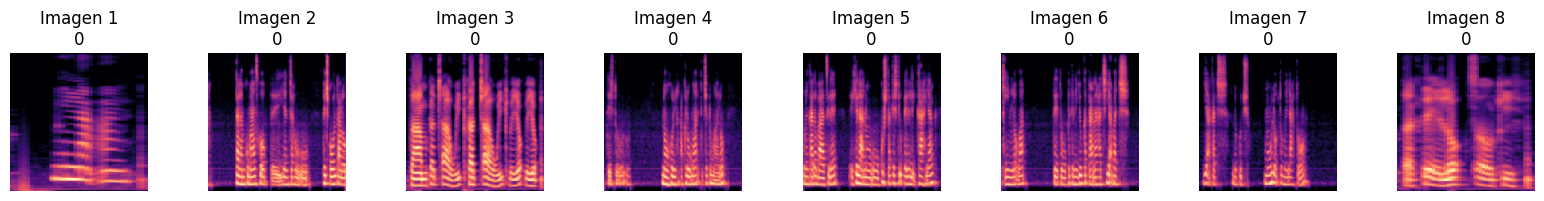

In [10]:
# ver 8 imágenes y etiquetas para la primera lengua: 0 español

display_images_and_labels(x,y,1)

Cargue las imágenes del espectrograma del segundo idioma, agréguelas a la lista denominada `x` y etiquételas con 1.

In [11]:
images, labels = load_images_from_path(f"/content/drive/MyDrive/spectograms/spanish_no_silence", 1)

x += images
y += labels

In [12]:
# imprime número de imágenes y etiquetas
print(len(x))
print(len(y))

2800
2800


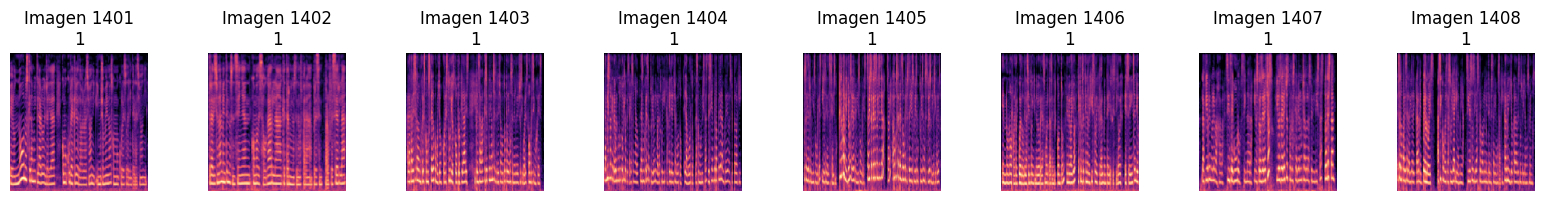

In [13]:
# ver 8 imagenes y etiquetas para la segunda lengua: 1 maya

display_images_and_labels(x,y,numero_audios_usados + 1)

Divida las imágenes y las etiquetas en tres conjuntos de datos: uno para **entrenamiento**, otro para **validación** y otro para **prueba**. Luego, divida los valores de los píxeles entre 255 y codifique las etiquetas con una sola variable usando la función [to_categorical](https://keras.io/api/utils/python_utils/#to_categorical-function) de Keras.

In [14]:
# Define los parámetros para la división de datos

split_usado = {"train":80, "validation":10, "test":10}
split_seed = 1  # 0 no reproducible, 1 reproducir la misma división de datos

In [15]:
# prompt: divide en 3 el dataset x and y para usar como train val, usar los porcentajes guardados en el diccionario split_usado

import numpy as np
from sklearn.model_selection import train_test_split

# Convert lists to numpy arrays
x = np.array(x)
y = np.array(y)

# Determine the sizes for each split based on the percentages
train_size = split_usado["train"] / 100
val_size = split_usado["validation"] / 100
test_size = split_usado["test"] / 100

# First split: separate out the test set
x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=test_size, random_state=split_seed, stratify=y
)

# Calculate the proportion of validation data relative to the remaining data
# (train_val_size = 1 - test_size)
val_size_relative = val_size / (train_size + val_size)

# Second split: separate out the training and validation sets from the remaining data
x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=val_size_relative, random_state=split_seed, stratify=y_train_val
)

# Print the shapes of the resulting datasets to verify the split
print(f"Shape of x_train: {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_val: {x_val.shape}")
print(f"Shape of y_val: {y_val.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of x_train: (2240, 224, 224, 3)
Shape of y_train: (2240,)
Shape of x_val: (280, 224, 224, 3)
Shape of y_val: (280,)
Shape of x_test: (280, 224, 224, 3)
Shape of y_test: (280,)


In [16]:
y_val

array([0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Luego, divida los valores de los píxeles por 255 y codifique las etiquetas con una sola codificación utilizando la función to_categorical de Keras.

In [17]:
# prompt: Then divide the pixel values by 255 and one-hot-encode the labels using Keras's to_categorical function.

from keras.utils import to_categorical

# Divide pixel values by 255
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, num_classes=len(languages))
y_val = to_categorical(y_val, num_classes=len(languages))
y_test = to_categorical(y_test, num_classes=len(languages))

# Print the shapes of the resulting datasets to verify the transformation
print(f"Shape of x_train after scaling: {x_train.shape}")
print(f"Shape of y_train after one-hot encoding: {y_train.shape}")
print(f"Shape of x_val after scaling: {x_val.shape}")
print(f"Shape of y_val after one-hot encoding: {y_val.shape}")
print(f"Shape of x_test after scaling: {x_test.shape}")
print(f"Shape of y_test after one-hot encoding: {y_test.shape}")

Shape of x_train after scaling: (2240, 224, 224, 3)
Shape of y_train after one-hot encoding: (2240, 2)
Shape of x_val after scaling: (280, 224, 224, 3)
Shape of y_val after one-hot encoding: (280, 2)
Shape of x_test after scaling: (280, 224, 224, 3)
Shape of y_test after one-hot encoding: (280, 2)


In [18]:
y_val

array([[1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.

## Construir y entrenar una CNN (convolutional neural network = red neuronal convolucional) con aprendizaje por transferencia

La clasificación de imágenes de vanguardia no se realiza típicamente con redes neuronales tradicionales. Más bien, se lleva a cabo con redes neuronales convolucionales que utilizan [capas de convolución](https://machinelearningmastery.com/convolutional-layers-for-deep-learning-neural-networks/) para extraer características de las imágenes y [capas de pooling](https://machinelearningmastery.com/pooling-layers-for-convolutional-neural-networks/) para reducir el tamaño de las imágenes de modo que las características puedan detectarse a varias resoluciones.

La siguiente tarea es construir una CNN que contenga una serie de capas de convolución y pooling para la extracción de características, un par de capas completamente conectadas para la clasificación, y una capa softmax que emita probabilidades para cada clase, y entrenarla con imágenes de espectrogramas y etiquetas. Comencemos definiendo la CNN.


El aprendizaje por transferencia o [Transfer learning](https://towardsdatascience.com/a-comprehensive-hands-on-guide-to-transfer-learning-with-real-world-applications-in-deep-learning-212bf3b2f27a) es una técnica poderosa que permite que CNN sofisticadas entrenadas por Google, Microsoft y otros en GPUs se reutilicen para resolver problemas de dominio específico. Muchas CNN pre-entrenadas están disponibles en el dominio público, y varias se incluyen con Keras.

Por ejmplo, [`MobileNetV2`](https://keras.io/api/applications/mobilenet/) es una CNN pre-entrenada de Google que está optimizada para dispositivos móviles, para extraer características de las imágenes de espectrogramas.

MobileNetV2 requiere menos potencia de procesamiento y tiene una menor huella de memoria que las CNN como ResNet50V2. Por eso es ideal para dispositivos móviles. Puedes aprender más sobre ella en el [Google AI blog](https://ai.googleblog.com/2018/04/mobilenetv2-next-generation-of-on.html).


Comienza llamando a la función [MobileNetV2 de Keras](https://keras.io/api/applications/mobilenet/) para instanciar MobileNetV2 sin las capas de clasificación.

Utiliza la función  [preprocess_input](https://www.tensorflow.org/api_docs/python/tf/keras/applications/mobilenet/preprocess_input) para preprocesar las imágenes de entrenamiento y prueba.

Luego, ejecuta ambos conjuntos de datos a través de MobileNetV2 para extraer características.

In [19]:
# define el modelo a utilizar
used_model = "EfficientNetB0"

# import tensorflow as tf

if used_model == "ResNet152V2":
    from tensorflow.keras.applications import ResNet152V2
    from tensorflow.keras.applications.resnet_v2 import preprocess_input
    base_model = ResNet152V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
elif used_model == "MobileNetV2":
    from tensorflow.keras.applications import MobileNetV2
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
elif used_model == "EfficientNetB0":
    from tensorflow.keras.applications import EfficientNetB0
    from tensorflow.keras.applications.efficientnet import preprocess_input
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
else:
    raise ValueError(f"Unsupported model: {used_model}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


* Congela el modelo para desactivar el entrenamiento de las capas del modelo base.
* Realiza un preprocesamiento para que los datos de entrada del modelo preentrenado tengan las mismas características que los datos con los que se entrenó originalmente. Normalmnte hace un escalado y desplazamiento de los pixeles.
* Extrae las características relevantes, que son representaciones de alto nivel que el modelo base ha extraído de las imágenes.

In [20]:
# Freeze the base model initially
base_model.trainable = False

# Preprocess the data
x_train_norm = preprocess_input(x_train)
x_val_norm = preprocess_input(x_val)
x_test_norm = preprocess_input(x_test)

# Extract features using the base model
x_train_features = base_model.predict(x_train_norm)
x_val_features = base_model.predict(x_val_norm)
x_test_features = base_model.predict(x_test_norm)

print(f"Shape of train features: {x_train_features.shape}")
print(f"Shape of val features: {x_val_features.shape}")
print(f"Shape of test features: {x_test_features.shape}")

# Unfreeze the base model for fine-tuning
base_model.trainable = True

70/70 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Shape of train features: (2240, 7, 7, 1280)
Shape of val features: (280, 7, 7, 1280)
Shape of test features: (280, 7, 7, 1280)


Explicación del código anterior:

1.  **Transfer Learning (Aprendizaje por transferencia):** usa una red neuronal pre-entrenada en un conjunto de datos muy grande (como ImageNet) como punto de partida para la tarea de clasificación de espectrogramas. Estas redes pre-entrenadas ya han aprendido a reconocer características visuales genéricas (bordes, texturas, formas, etc.).

2.  **Congelar Capas (`trainable = False`):** Al establecer `base_model.trainable = False`, estás indicando a TensorFlow/Keras que no modifique los pesos de las capas dentro de `base_model` durante el proceso de entrenamiento. Esto significa que el modelo base se utiliza únicamente como un extractor de características fijas.

3. **Preprocesamiento ('preprocess_input'):** Para que los datos de entrada tengan las mismas características que los datos con los que se entrenó originalmente. Esto es crucial para que el aprendizaje por transferencia funcione eficazmente, permitiendo que el modelo preentrenado extraiga características significativas. Realiza dos tipos de normalizaciones:

* Escalado: Escala los valores de los píxeles de las imágenes. Los modelos de ImageNet se entrenaron con imágenes donde los valores de los píxeles se escalaron de una manera específica (a menudo centrados alrededor de 0 con una desviación estándar determinada). Esta función aplica ese mismo escalado a las imágenes para que coincidan con el formato de entrada que espera el modelo preentrenado.
* Desplazamiento: También puede aplicar un desplazamiento a los valores de los píxeles.

4.  **Extracción de Características:** Después de "congelar" el modelo base, procesas tus datos de espectrogramas (`x_train_norm`, `x_val_norm`, `x_test_norm`) a través de él usando `base_model.predict(...)`. El resultado (`x_train_features`, etc.) son las representaciones de alto nivel que el modelo base ha extraído de tus imágenes.

5.  **Propósito:** El objetivo es usar estas características extraídas para entrenar una nueva parte del modelo (ver más abajo) para realizar la clasificación específica de las clases de audio (lenguas). Al congelar el modelo base, te aseguras de que las representaciones genéricas aprendidas no se "olviden" ni se modifiquen demasiado para tu conjunto de datos más pequeño, lo que ayuda a evitar el sobreajuste y acelera el entrenamiento de las capas nuevas o descongeladas.

En resumen, `base_model.trainable = False` evita que los pesos de la red pre-entrenada se actualicen durante el entrenamiento, permitiéndote utilizarla como un extractor de características estático para tus datos de espectrogramas.

## Definir una red neuronal para clasificar las características extraídas por el modelo

Definir los parámetros para entrenar un modelo simple de red neuronal secuencial para clasificación.

In [21]:
parameters = {"batch_size":20, "epochs":30, "learning_rate": 1e-4}

Define función para aumento de datos

In [22]:
# Create a dictionary to store data augmentation strategies
#data_augmentation_strategies = {
 #   "RandomFlip": "horizontal_and_vertical",
  #  "RandomRotation": 0.2,
   # "RandomZoom": 0.2,
    #"RandomContrast": 0.2,
#}

In [23]:
#import tensorflow as tf

# Define data augmentation layers
#data_augmentation = tf.keras.Sequential([
 #   tf.keras.layers.RandomFlip("horizontal_and_vertical"),
  #  tf.keras.layers.RandomRotation(0.2),
   # tf.keras.layers.RandomZoom(0.2),
    #tf.keras.layers.RandomContrast(factor=0.2), # Added RandomContrast
#])

# Añaden 5 capas nuevas a la red ya entrenada

In [24]:
from keras.models import Sequential
from keras.layers import Flatten, Dense, Dropout, BatchNormalization
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
import tensorflow as tf # Import tensorflow to use data_augmentation

# Define a lower learning rate for fine-tuning
fine_tune_learning_rate = parameters["learning_rate"] * 0.1 # Use a fraction of the initial learning rate

optimizer = Adam(learning_rate=fine_tune_learning_rate) # use the lower learning rate for fine-tuning

# inicializa un modelo secuencial, las capas se añaden una tras otra en una pila lineal
model = Sequential()

# Add data augmentation layer
# Note: Data augmentation should be applied before the base model in an end-to-end model
# For feature extraction approach, data augmentation should be applied to the input images (x_train, x_val, x_test)
# or build an end-to-end model including the base_model

# CAPA 1
# capa de aplanamiento que toma la salida multidimensional de la extracción de características (del modelo base) y la aplana en una matriz unidimensional,
# preparándola para las capas completamente conectadas.
model.add(Flatten(input_shape=x_train_features.shape[1:]))

# CAPA 2
# capa densa (completamente conectada) con 256 neuronas y una función de activación ReLU,
# incluye regularización L2 para ayudar a prevenir el sobreajuste
# L2 añade una penalización a la función de pérdida basada en los valores al cuadrado de los pesos

#model.add(Dense(256, activation='relu', kernel_regularizer=l2(1e-4)))
model.add(Dense(256, activation='relu', kernel_regularizer=l2(1e-4)))

# CAPA 3
# capa de normalización por lotes para estabilizar el proceso de entrenamiento y mejorar el rendimiento al normalizar las entradas de la siguiente
model.add(BatchNormalization())

# CAPA 4
# capa de abandono, establece aleatoriamente una fracción de las unidades de entrada a 0 durante el entrenamiento. Esta es otra técnica para evitar el sobreajuste.
model.add(Dropout(0.7))

# CAPA 5
# capa densa de salida con 2 neuronas (dos clases de lenguas) y una función de activación sigmoidea
model.add(Dense(2, activation='sigmoid'))

# configura el modelo para el entrenamiento, especifica el optimizador, la función de pérdida (binary_crossentropy para la clasificación binaria) y la métrica a evaluar (precisión)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# imprime un resumen de la arquitectura del modelo, incluyendo las capas, las formas de salida y el número de parámetros
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    16,056,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,058,114 (61.26 MB)

 Trainable params: 16,057,602 (61.25 MB)

 Non-trainable params: 512 (2.00 KB)

Entrenar la red con el conocimiento aprendido más las nuevas 5 capas


In [25]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist = model.fit(x_train_features, y_train, validation_data=(x_val_features, y_val), batch_size= parameters["batch_size"] , epochs=parameters["epochs"], callbacks=[early_stop])

Epoch 1/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7360 - loss: 0.6261 - val_accuracy: 0.5000 - val_loss: 0.7326
Epoch 2/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8114 - loss: 0.4952 - val_accuracy: 0.5000 - val_loss: 0.8290
Epoch 3/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8253 - loss: 0.4570 - val_accuracy: 0.7821 - val_loss: 0.6336
Epoch 4/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8585 - loss: 0.4050 - val_accuracy: 0.5357 - val_loss: 1.1710
Epoch 5/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8552 - loss: 0.3983 - val_accuracy: 0.5000 - val_loss: 1.9575
Epoch 6/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8672 - loss: 0.3815 - val_accuracy: 0.5000 - val_loss: 2.6995
Epoch 7/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8589 - loss: 0.3751 - val_accuracy: 0.5000 - val_loss: 5.1032
Epoch 8/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8655 - loss: 0.3804 - val_accuracy

Plot the training and validation accuracy.

[]

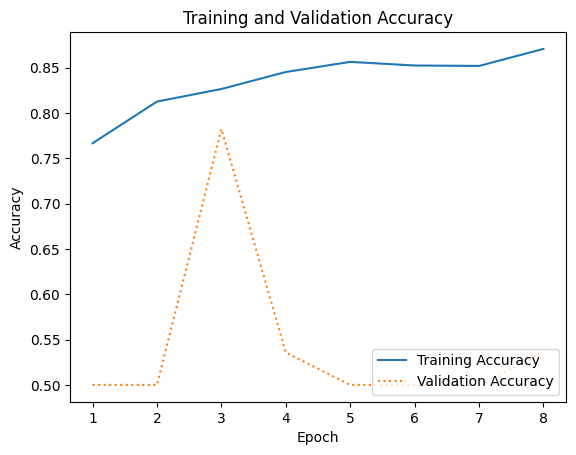

In [26]:

acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, '-', label='Training Accuracy')
plt.plot(epochs, val_acc, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.plot()

Run the validation images through the network and use a confusion matrix to assess the results.

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step


Text(109.44999999999997, 0.5, 'Actual label')

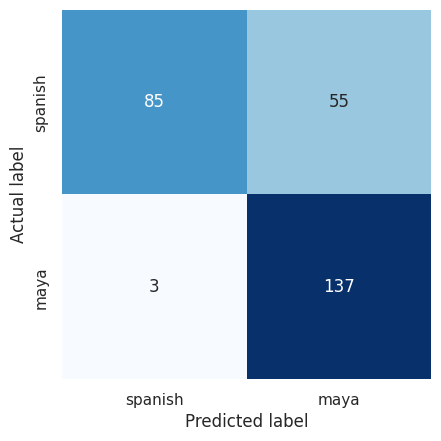

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
sns.set()

y_predicted = model.predict(x_test_features)
mat = confusion_matrix(y_test.argmax(axis=1), y_predicted.argmax(axis=1))
class_labels = ['spanish', 'maya']

sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)

plt.xlabel('Predicted label')
plt.ylabel('Actual label')

Get accuracy, recall, precision and f1 score metrics

In [28]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import numpy as np

y_pred = model.predict(x_test_features)

y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1) # Convert one-hot encoded y_test to class indices


accuracy = accuracy_score(y_test_classes, y_pred_classes)
recall = recall_score(y_test_classes, y_pred_classes)
precision = precision_score(y_test_classes, y_pred_classes)
f1 = f1_score(y_test_classes, y_pred_classes)

print(f"Accuracy: {accuracy}")
print(f"Recall: {recall}")
print(f"Precision: {precision}")
print(f"F1 Score: {f1}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Accuracy: 0.7928571428571428
Recall: 0.9785714285714285
Precision: 0.7135416666666666
F1 Score: 0.8253012048192772


## Registro de experimentos
Puedes usar los siguientes fragmentos de código para llevar un control de tus experimentos. Primero, crea un archivo CSV para mantener un registro de ellos.

In [29]:
import pandas as pd
try:
    df_log = pd.read_csv(f"{directorio_de_trabajo}/log.csv")
except FileNotFoundError:
    df_log = pd.DataFrame(columns=["ID_Exp", # contador de experimentos
                                   "Hash", # identificador único generado usando todos los campos
                                   "Languages", # lenguas que se entrenan
                                   "Audio_Folders_Used", # carpeta de audios
                                  "Image_Amount", # cantidad de audios por cada lengua
                                   "hasSilence", # false si los silencios fueron removidos con audacity
                                   "Audio_Length", # longitud de los audios, empty string if wasn't standarized, use int seconds otherwise
                                   "Balance", # indicar si se balancea al número de audios de la clase minoritaria: 0 no, /1, si
                                   "Audios_usados", # si se balanceó, cuántos audios por lengua
                                   "Model", # modelo entrenado
                                   "Data_augmentation", # estrategias de aumento de datos
                                   "Parameters", # batch_size, epochs y learning_rate
                                   "Split_usado", # division de los datos
                                   "Split_Seed",
                                   "Results", #: Accuracy, Recall, Precision, F1
                                   "Notes" # observaciones especiales
                                   ])

df_log.to_csv(f"{directorio_de_trabajo}/log.csv", index=False)

Ahora se crea un *hash* (identificador único) con las diferentes variables del experimento. Puedes usar el valor del hash y el registro para comprobar si usaste los mismos valores antes.

In [31]:
import hashlib

hash = hashlib.md5(f"{languages},{hasSilence},{audio_length},{balance},{numero_audios_usados},{used_model},{data_augmentation_strategies},{parameters},{split_usado},{split_seed}".encode()).hexdigest()
hash

'0ea155ff80467e48fe2fd721ba6b7b34'

Se guarda el experimento en la bitácora (archivo CSV)

In [33]:
import pandas as pd
df_log = pd.read_csv(f"{directorio_de_trabajo}/log.csv")

# Define the list of audio folders used
folder_path_list = [
    "spanish_no_silence",
    "mayan_without_silence"
]

# Calcula ID experimento
ID_Exp = f"EXP{len(df_log)}"


new_exp = {
    "ID_Exp": ID_Exp,
    "Hash": hash,
    "Languages": languages,
    "Audio_Folders_Used": folder_path_list,
    "Image_Amount": image_amount,
    "hasSilence": hasSilence,
    "Audio_Length": audio_length,
    "Balance": balance,
    "Audios_usados": numero_audios_usados, # si se balanceó, cuántos audios por lengua
    "Model": used_model,
   # "Data_augmentation": data_augmentation_strategies,
    "Parameters": parameters,
    "Split_usado": split_usado, # division de los datos
    "Split_Seed": split_seed,
    "Results": f"Accuracy: {accuracy} Recall: {recall} Precision: {precision} F1: {f1}",
    "Notes": "tratando de reproducir los resultados del paper a partir de los espectogramas sin silencios"
}

df_log = pd.concat([df_log, pd.DataFrame([new_exp])], ignore_index=True)
df_log.to_csv(f"{directorio_de_trabajo}/log.csv",index=False)

# Guarda el modelo
Saving it as a .keras file, allows you use the trained model in the future

In [34]:
# prompt: salvar el modelo en el directorio de trabajo

import os

# Create the experiments directory if it doesn't exist
experiments_dir = os.path.join(directorio_de_trabajo, "experimentos")
if not os.path.exists(experiments_dir):
    os.makedirs(experiments_dir)

# Save the model
model.save(f"{experiments_dir}/{ID_Exp}_model.keras")
print(f"Model saved to: {experiments_dir}/{ID_Exp}_model.keras")

Model saved to: /content/drive/MyDrive/spectograms/experimentos/EXP39_model.keras


Guarda el notebook manualmente anteponiendi {ID_Exp}_

Experiment results saved to: /content/drive/MyDrive/spectograms/experimentos/EXP39_results.txt
Accuracy plot saved to: /content/drive/MyDrive/spectograms/experimentos/EXP39_accuracy_plot.png


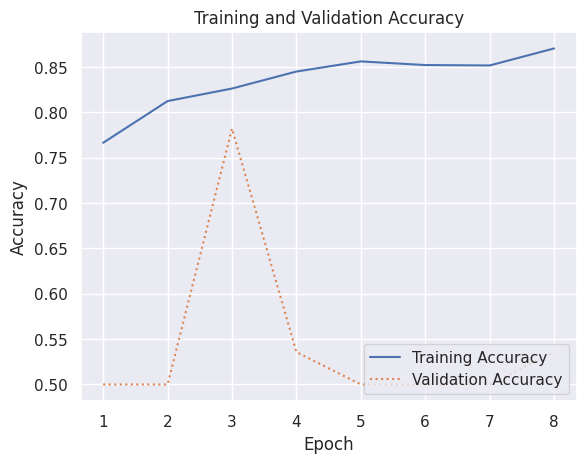

In [37]:
# Save experiment results to a text file
results_file_path = os.path.join(experiments_dir, f"{ID_Exp}_results.txt")
with open(results_file_path, "w") as f:
    f.write(f"Experiment ID: {ID_Exp}\n")
    f.write(f"Model Used: {used_model}\n")
    f.write(f"Parameters: {parameters}\n")
  #  f.write(f"Data Augmentation Strategies: {data_augmentation_strategies}\n")
    f.write(f"Split Used: {split_usado}\n")
    f.write(f"Split Seed: {split_seed}\n")
    f.write(f"Results:\n")
    f.write(f"  Accuracy: {accuracy}\n")
    f.write(f"  Recall: {recall}\n")
    f.write(f"  Precision: {precision}\n")
    f.write(f"  F1 Score: {f1}\n")
    f.write(f"Notes: tratando de reproducir los resultados del paper a partir de los espectogramas sin silencios\n")

    # Write the confusion matrix as text
    f.write("\nConfusion Matrix:\n")
    f.write(pd.DataFrame(mat, index=class_labels, columns=class_labels).to_string())

    # Write the accuracy plot data as text
    f.write("\nTraining and Validation Accuracy Data:\n")
    f.write("Epoch,Training Accuracy,Validation Accuracy\n")
    for i in range(len(epochs)):
        f.write(f"{epochs[i]},{acc[i]},{val_acc[i]}\n")


# Save the training and validation accuracy plot as an image
plot_file_path = os.path.join(experiments_dir, f"{ID_Exp}_accuracy_plot.png")
plt.figure() # Create a new figure to avoid overwriting the confusion matrix plot
plt.plot(epochs, acc, '-', label='Training Accuracy')
plt.plot(epochs, val_acc, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.savefig(plot_file_path)

# Add the plot file path to the results file
with open(results_file_path, "a") as f:
    f.write(f"\nAccuracy Plot Image: {plot_file_path}\n")


print(f"Experiment results saved to: {results_file_path}")
print(f"Accuracy plot saved to: {plot_file_path}")